# Model Serving: REST, gRPC, and Streaming
## Live Demo — Instructor-Run
**ML System Design and LLMOps | Week 2, Session 2**

We've trained models and engineered features. Today we're going to look at the serving layer — how models get from a `.pkl` file to a response that a product user actually receives.

Four things we'll cover:
1. Wrapping a sklearn model as a FastAPI endpoint — what the serving code actually looks like
2. The latency percentile problem — why mean latency is a lie
3. Batch vs online prediction — when to use each, and by how much they differ
4. BentoML — a quick look at the production serving abstraction

## Part 1: Wrapping a Model as a FastAPI Endpoint
*This code runs in a terminal, not a notebook — but let's read it carefully*

We're going to write the full serving code for a sklearn classifier. You'd run this with `uvicorn serve:app --host 0.0.0.0 --port 8000`. I'll show it here as a code cell, but flag clearly that it needs a server process.

In [1]:
# First, let's train and save the model we'll serve
import pickle
import numpy as np
from sklearn.datasets import load_iris
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=500, random_state=42))
])
pipeline.fit(X_train, y_train)

accuracy = accuracy_score(y_test, pipeline.predict(X_test))
print(f"Model trained. Accuracy: {accuracy:.3f}")

model_path = "/tmp/iris_pipeline.pkl"
with open(model_path, "wb") as f:
    pickle.dump(pipeline, f)
print(f"Pipeline saved to: {model_path}")

Model trained. Accuracy: 1.000
Pipeline saved to: /tmp/iris_pipeline.pkl


In [2]:
# ── FastAPI serving code — READ ONLY, not executed in notebook ────────────────
# This is what you'd save as 'serve.py' and run in a terminal.
# We're showing it here to understand what serving code actually looks like.

serving_code = '''
# ── serve.py ─────────────────────────────────────────────────────────────────
# pip install fastapi uvicorn
# Run with: uvicorn serve:app --host 0.0.0.0 --port 8000

from fastapi import FastAPI
from pydantic import BaseModel
import pickle, numpy as np

app = FastAPI()

# Load model once at startup — not on every request
with open('/tmp/iris_pipeline.pkl', 'rb') as f:
    MODEL = pickle.load(f)

CLASS_NAMES = ['setosa', 'versicolor', 'virginica']

class PredictRequest(BaseModel):
    sepal_length: float
    sepal_width: float
    petal_length: float
    petal_width: float

class PredictResponse(BaseModel):
    predicted_class: str
    confidence: float
    probabilities: dict

@app.post('/predict', response_model=PredictResponse)
def predict(request: PredictRequest):
    features = np.array([[request.sepal_length, request.sepal_width,
                           request.petal_length, request.petal_width]])
    proba = MODEL.predict_proba(features)[0]
    pred_idx = proba.argmax()
    return PredictResponse(
        predicted_class=CLASS_NAMES[pred_idx],
        confidence=float(proba[pred_idx]),
        probabilities={name: float(p) for name, p in zip(CLASS_NAMES, proba)}
    )

@app.get('/health')
def health():
    return {'status': 'ok', 'model_loaded': MODEL is not None}

# ─────────────────────────────────────────────────────────────────────────────
'''

print("=== FastAPI Serving Code (run in terminal, not here) ===")
print(serving_code)

print("Example request (curl):")
print("  curl -X POST http://localhost:8000/predict \\")
print("    -H 'Content-Type: application/json' \\")
print("    -d '{\"sepal_length\": 5.1, \"sepal_width\": 3.5, \"petal_length\": 1.4, \"petal_width\": 0.2}'")
print()
print("Expected response:")
print('  {"predicted_class": "setosa", "confidence": 0.987, "probabilities": {...}}')

=== FastAPI Serving Code (run in terminal, not here) ===

# ── serve.py ─────────────────────────────────────────────────────────────────
# pip install fastapi uvicorn
# Run with: uvicorn serve:app --host 0.0.0.0 --port 8000

from fastapi import FastAPI
from pydantic import BaseModel
import pickle, numpy as np

app = FastAPI()

# Load model once at startup — not on every request
with open('/tmp/iris_pipeline.pkl', 'rb') as f:
    MODEL = pickle.load(f)

CLASS_NAMES = ['setosa', 'versicolor', 'virginica']

class PredictRequest(BaseModel):
    sepal_length: float
    sepal_width: float
    petal_length: float
    petal_width: float

class PredictResponse(BaseModel):
    predicted_class: str
    confidence: float
    probabilities: dict

@app.post('/predict', response_model=PredictResponse)
def predict(request: PredictRequest):
    features = np.array([[request.sepal_length, request.sepal_width,
                           request.petal_length, request.petal_width]])
    proba = MODEL.pred

### Key design decisions in the serving code

1. **Model loaded at startup** — `MODEL = pickle.load(...)` runs once. If you loaded it inside `predict()`, every request would re-read disk. At 1000 req/s that's catastrophic.
2. **Typed request/response** — Pydantic models give you free input validation and API documentation.
3. **Health endpoint** — Load balancers use `/health` to know when to route traffic. Without it, a crashed pod still receives requests.
4. **Probabilities returned** — Downstream systems often need the full distribution, not just the top prediction.

---
## Part 2: The Latency Percentile Problem
*Why "average latency = 12ms" tells you almost nothing*

We're going to simulate a realistic latency distribution — the kind you'd see from a model serving endpoint under load. Then we'll show why mean latency is a dangerous metric and what to use instead.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n_requests = 1000

# Realistic latency distribution:
# Most requests are fast (lognormal), but a small fraction hit slow paths
# (GC pauses, cold cache, model reloading, etc.)
normal_latencies = np.random.lognormal(mean=2.5, sigma=0.4, size=int(n_requests * 0.97))  # ms
outlier_latencies = np.random.uniform(200, 1000, size=int(n_requests * 0.03))  # GC/cold start
latencies = np.concatenate([normal_latencies, outlier_latencies])
np.random.shuffle(latencies)

# Compute statistics
mean_lat = np.mean(latencies)
p50 = np.percentile(latencies, 50)
p75 = np.percentile(latencies, 75)
p90 = np.percentile(latencies, 90)
p95 = np.percentile(latencies, 95)
p99 = np.percentile(latencies, 99)
max_lat = np.max(latencies)

print("=== Latency Distribution Analysis ===")
print(f"{n_requests} simulated requests to our prediction endpoint")
print()
print("--- What the dashboard usually shows ---")
print(f"  Mean latency:    {mean_lat:.1f} ms")
print(f"  Median (p50):    {p50:.1f} ms")
print()
print("--- What actually matters to users ---")
print(f"  p75 latency:     {p75:.1f} ms")
print(f"  p90 latency:     {p90:.1f} ms")
print(f"  p95 latency:     {p95:.1f} ms  <-- 1 in 20 requests")
print(f"  p99 latency:    {p99:.1f} ms  <-- 1 in 100 requests")
print(f"  Max latency:    {max_lat:.1f} ms")
print()
print("--- The problem ---")
print(f"  Mean ({mean_lat:.1f}ms) looks fine.")
print(f"  But 1% of requests (p99={p99:.1f}ms) is unacceptably slow.")
print(f"  At 100 req/s, that's 1 bad experience per second.")

# Demonstrate: remove outliers and show the mean barely changes
normal_only_mean = np.mean(normal_latencies)
normal_only_p99 = np.percentile(normal_latencies, 99)

print()
print("--- Why the mean is misleading ---")
print(f"  Without outliers: mean={normal_only_mean:.1f}ms, p99={normal_only_p99:.1f}ms")
print(f"  With outliers:    mean={mean_lat:.1f}ms, p99={p99:.1f}ms")
print(f"  The mean moved by {mean_lat - normal_only_mean:.1f}ms. The p99 moved by {p99 - normal_only_p99:.1f}ms.")
print(f"  A user experiencing a p99 request feels {p99 - normal_only_p99:.0f}ms extra latency.")
print(f"  The mean hides this completely.")

print()
print("SLA recommendation: monitor p50, p95, p99 — not mean.")

=== Latency Distribution Analysis ===
1000 simulated requests to our prediction endpoint

--- What the dashboard usually shows ---
  Mean latency:    28.8 ms
  Median (p50):    12.5 ms

--- What actually matters to users ---
  p75 latency:     16.2 ms
  p90 latency:     22.4 ms
  p95 latency:     28.2 ms  <-- 1 in 20 requests
  p99 latency:    614.5 ms  <-- 1 in 100 requests
  Max latency:    989.3 ms

--- The problem ---
  Mean (28.8ms) looks fine.
  But 1% of requests (p99=614.5ms) is unacceptably slow.
  At 100 req/s, that's 1 bad experience per second.

--- Why the mean is misleading ---
  Without outliers: mean=13.3ms, p99=31.3ms
  With outliers:    mean=28.8ms, p99=614.5ms
  The mean moved by 15.5ms. The p99 moved by 583.2ms.
  A user experiencing a p99 request feels 583ms extra latency.
  The mean hides this completely.

SLA recommendation: monitor p50, p95, p99 — not mean.


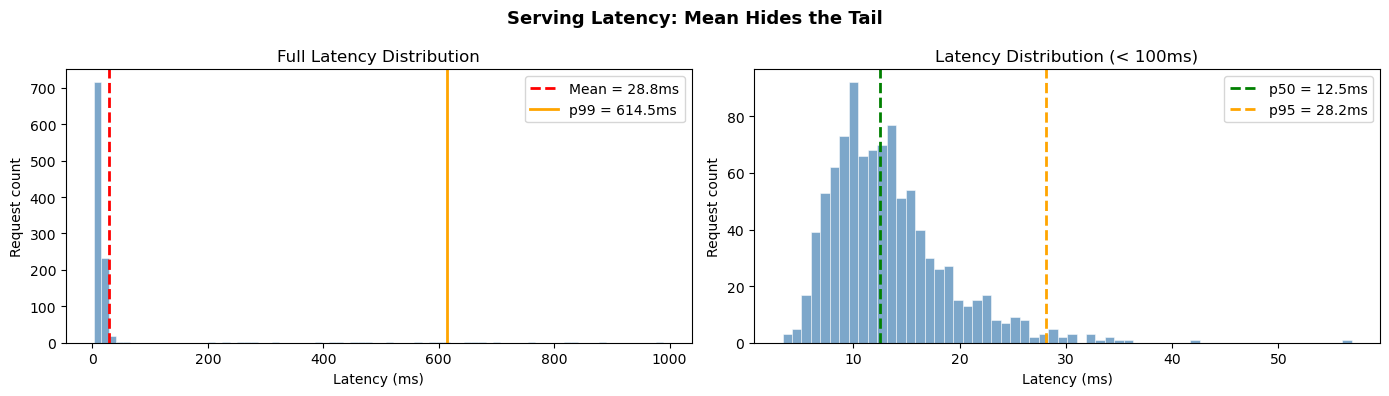

In [4]:
# Visualise the distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: full distribution (log scale to show the tail)
axes[0].hist(latencies, bins=80, color='steelblue', alpha=0.7, edgecolor='white', linewidth=0.5)
axes[0].axvline(mean_lat, color='red', linewidth=2, linestyle='--', label=f'Mean = {mean_lat:.1f}ms')
axes[0].axvline(p99, color='orange', linewidth=2, linestyle='-', label=f'p99 = {p99:.1f}ms')
axes[0].set_xlabel('Latency (ms)')
axes[0].set_ylabel('Request count')
axes[0].set_title('Full Latency Distribution')
axes[0].legend()

# Right: zoom in on the "normal" range (< 100ms) to see the bulk
axes[1].hist(latencies[latencies < 100], bins=60, color='steelblue', alpha=0.7, edgecolor='white', linewidth=0.5)
for pct, val, color in [(50, p50, 'green'), (95, p95, 'orange'), (99, p99, 'red')]:
    if val < 100:
        axes[1].axvline(val, color=color, linewidth=2, linestyle='--', label=f'p{pct} = {val:.1f}ms')
axes[1].set_xlabel('Latency (ms)')
axes[1].set_ylabel('Request count')
axes[1].set_title('Latency Distribution (< 100ms)')
axes[1].legend()

plt.suptitle('Serving Latency: Mean Hides the Tail', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Part 3: Batch Prediction vs Online Prediction
*Precompute everything, or compute on demand — the tradeoff in numbers*

We're going to implement both approaches for a recommender system: batch precomputes recommendations for all users and stores them; online computes on request. We'll time both and discuss when each makes sense.

In [5]:
import numpy as np
import time

np.random.seed(42)

n_users = 10_000
n_items = 500
n_features = 20
top_k = 10

# Simulate user and item feature matrices
user_features = np.random.randn(n_users, n_features).astype(np.float32)
item_features = np.random.randn(n_items, n_features).astype(np.float32)

# The scoring function: dot product similarity (simplified two-tower)
def score_items_for_user(user_feat, item_feats, top_k=10):
    """Return top-k item indices for a given user feature vector."""
    scores = item_feats @ user_feat  # (n_items,)
    top_indices = np.argpartition(scores, -top_k)[-top_k:]
    return top_indices[np.argsort(scores[top_indices])[::-1]]

item_names = [f"item_{i:03d}" for i in range(n_items)]

# ── Approach A: Batch prediction ─────────────────────────────────────────────
print("=== Batch vs Online Prediction ===")
print(f"{n_users:,} users, {n_items:,} items, {n_features} features")
print()
print("--- Batch Prediction ---")
print(f"Running batch job for all {n_users:,} users...")

batch_start = time.perf_counter()
# Precompute recommendations for every user
recommendation_store = {}  # in prod: Redis or DynamoDB
for user_id in range(n_users):
    rec_indices = score_items_for_user(user_features[user_id], item_features, top_k)
    recommendation_store[user_id] = [item_names[i] for i in rec_indices]
batch_time = time.perf_counter() - batch_start

print("Batch job complete.")
print(f"  Total batch time:              {batch_time:.3f} s")
print(f"  Per-user precompute time:      {batch_time / n_users * 1000:.3f} ms")

# Storage estimate: 10 item strings per user
storage_bytes = sum(sum(len(r) for r in recs) for recs in recommendation_store.values())
print(f"  Storage required:             {storage_bytes/1024:.1f} KB (top-10 recs per user)")

# Batch serving: just a dict lookup
query_user = 7342
print(f"\nServing a request for user_{query_user}:")
t0 = time.perf_counter()
batch_result = recommendation_store[query_user]
batch_serve_time = time.perf_counter() - t0
print(f"  Batch serving time (dict lookup): {batch_serve_time*1000:.3f} ms")
print(f"  Recommendations: {batch_result[:5]}")

# ── Approach B: Online prediction ─────────────────────────────────────────────
print()
print("--- Online Prediction ---")
print(f"Request arrives for user_{query_user}...")

t0 = time.perf_counter()
online_recs_idx = score_items_for_user(user_features[query_user], item_features, top_k)
online_result = [item_names[i] for i in online_recs_idx]
online_time = time.perf_counter() - t0

print(f"  Online prediction time (compute on demand): {online_time*1000:.3f} ms")
print(f"  Recommendations: {online_result[:5]}")

print()
print("--- Comparison ---")
print(f"{'':24} {'Batch':14} {'Online'}")
print(f"  {'Serving latency:':<22} {batch_serve_time*1000:.3f} ms       {online_time*1000:.3f} ms")
print(f"  {'Staleness:':<22} {'up to 24h':<14} {'0ms (real-time)'}")
print(f"  {'New user handling:':<22} {'fails':<14} {'works immediately'}")
print(f"  {'Feature freshness:':<22} {'stale':<14} {'fresh'}")
print(f"  {'Compute cost:':<22} {'amortized':<14} {'per-request'}")
print()
print("When to use batch: recommendations, reports, email campaigns, low-traffic endpoints")
print("When to use online: search, fraud detection, dynamic pricing, real-time feeds")

=== Batch vs Online Prediction ===
10,000 users, 500 items, 20 features

--- Batch Prediction ---
Running batch job for all 10,000 users...
Batch job complete.
  Total batch time:              0.253 s
  Per-user precompute time:      0.025 ms
  Storage required:             781.2 KB (top-10 recs per user)

Serving a request for user_7342:
  Batch serving time (dict lookup): 0.036 ms
  Recommendations: ['item_381', 'item_250', 'item_119', 'item_239', 'item_453']

--- Online Prediction ---
Request arrives for user_7342...
  Online prediction time (compute on demand): 0.141 ms
  Recommendations: ['item_381', 'item_250', 'item_119', 'item_239', 'item_453']

--- Comparison ---
                         Batch          Online
  Serving latency:       0.036 ms       0.141 ms
  Staleness:             up to 24h      0ms (real-time)
  New user handling:     fails          works immediately
  Feature freshness:     stale          fresh
  Compute cost:          amortized      per-request

When to us

---
## Part 4: BentoML — The Production Serving Abstraction
*What a real serving framework looks like*

FastAPI is great for small services. For production ML serving, you want something that handles:
- Model versioning and registry
- Adaptive batching (auto-batch incoming requests to maximize GPU utilization)
- Runner APIs (separate CPU pre/post-processing from GPU inference)
- Docker/Kubernetes packaging out of the box

BentoML does all of this. Let's read through a minimal example.

In [7]:
# ── BentoML code walkthrough ──────────────────────────────────────────────────
# This is a conceptual walkthrough. To run it:
#   pip install bentoml
# Then copy the service code to a file called service.py and run:
#   bentoml serve service:svc --reload

print("=== BentoML Walkthrough (conceptual — install bentoml to run) ===")
print()

print("Step 1: Save model to BentoML model store")
print("  bentoml.sklearn.save_model('iris_classifier', pipeline)")
print("  → Stores model with version tag, metadata, and signatures")
print("  → Model is now in the local BentoML store, addressable by name + version")
print()

bentoml_service_code = '''\
import bentoml
import numpy as np
from bentoml.io import NumpyNdarray, JSON

iris_runner = bentoml.sklearn.get('iris_classifier:latest').to_runner()

svc = bentoml.Service('iris_service', runners=[iris_runner])

@svc.api(input=NumpyNdarray(), output=JSON())
async def classify(features: np.ndarray) -> dict:
    # Runner call is async — BentoML handles adaptive batching
    proba = await iris_runner.predict_proba.async_run(features)
    return {'class': int(proba.argmax()), 'confidence': float(proba.max())}'''

print("Step 2: Define a BentoML Service")
print("-" * 60)
print(bentoml_service_code)
print("-" * 60)
print()

print("Step 3: Build a Bento (deployable artifact)")
print("  bentoml build")
print("  → Packages model + service + dependencies into a single artifact")
print()

print("Step 4: Deploy")
print("  bentoml containerize iris_service:latest")
print("  → Produces a Docker image ready for Kubernetes / cloud deployment")
print()

print("Key BentoML concepts:")
print("  Runner:  async wrapper around inference that enables adaptive batching")
print("  Service: defines the API endpoints and which runners they use")
print("  Bento:   the deployable package (model + code + dependencies)")
print("  Store:   versioned model registry on local disk or remote")

=== BentoML Walkthrough (conceptual — install bentoml to run) ===

Step 1: Save model to BentoML model store
  bentoml.sklearn.save_model('iris_classifier', pipeline)
  → Stores model with version tag, metadata, and signatures
  → Model is now in the local BentoML store, addressable by name + version

Step 2: Define a BentoML Service
------------------------------------------------------------
import bentoml
import numpy as np
from bentoml.io import NumpyNdarray, JSON

iris_runner = bentoml.sklearn.get('iris_classifier:latest').to_runner()

svc = bentoml.Service('iris_service', runners=[iris_runner])

@svc.api(input=NumpyNdarray(), output=JSON())
async def classify(features: np.ndarray) -> dict:
    # Runner call is async — BentoML handles adaptive batching
    proba = await iris_runner.predict_proba.async_run(features)
    return {'class': int(proba.argmax()), 'confidence': float(proba.max())}
------------------------------------------------------------

Step 3: Build a Bento (deploya

### Why adaptive batching matters

A GPU can process 64 examples in almost the same time as 1 example (matrix multiplication is parallelized). If requests arrive one at a time, you're using 1/64th of your GPU capacity.

Adaptive batching: the runner waits a configurable number of milliseconds (e.g., 5ms), collects all incoming requests, batches them, runs inference once, and returns results to each caller. At 1000 req/s, this can multiply throughput by 10-50x with negligible latency increase.

---

**Discussion:** We've seen batch precompute (zero serving latency, stale features) and online compute (fresh features, per-request cost). Describe a system that uses **both** — when would you serve from the precomputed cache, and when would you fall back to online computation?